In [1]:
import torch
from transformers import AutoTokenizer

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

In [3]:
fichier_data = "../data/raw/dereev_data_3_deduplicated.xlsx"

df = pd.read_excel(fichier_data)

colonne_notes = "cn_notes"
colonne_reev = 'reev_classe'
df[colonne_notes] = df[colonne_notes].astype(str)

print(f"{len(df)} notes ont été trouvées.")

1721 notes ont été trouvées.


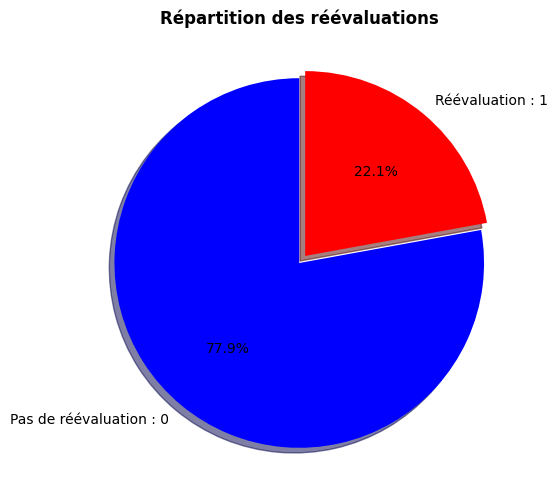

In [4]:
### PIE CHART RÉPARTITION DES CLASSES

plt.figure(figsize=(8,6))
repartition = df[colonne_reev].value_counts()
plt.pie(repartition, labels=["Pas de réévaluation : 0", "Réévaluation : 1"],
        autopct='%1.1f%%', startangle=90, explode=(0, 0.05), shadow=True, colors=["blue", 'red'])

plt.title("Répartition des réévaluations", fontweight='bold')
plt.show()

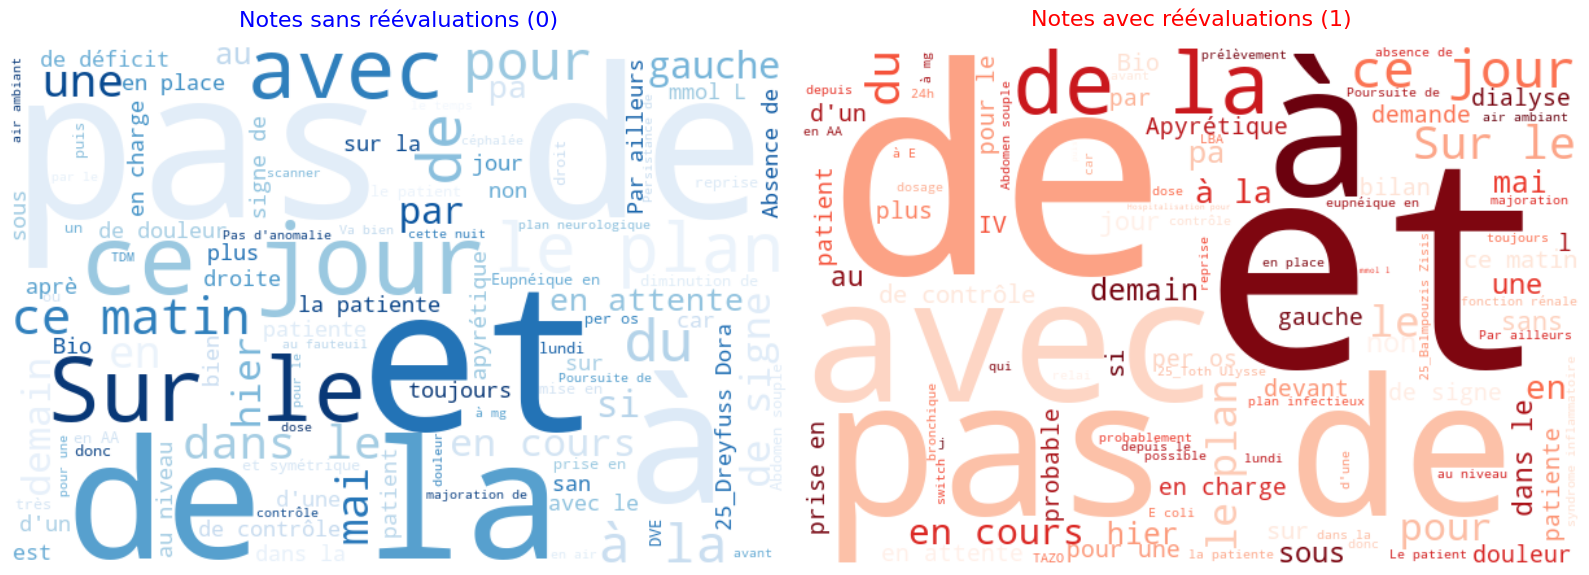

In [4]:
### WORDCLOUD 
### WORDCLOUD 

notes_0 = df.loc[df[colonne_reev] == 0, colonne_notes].dropna().astype(str)
notes_1 = df.loc[df[colonne_reev] == 1, colonne_notes].dropna().astype(str)

texte_0 = " ".join(notes_0)
texte_1 = " ".join(notes_1)

wc_0 = WordCloud(
    width=600,
    height=400,
    background_color="white",
    colormap="Blues",
    max_words=100
).generate(texte_0)

wc_1 = WordCloud(
    width=600,
    height=400,
    background_color="white",
    colormap="Reds",
    max_words=100
).generate(texte_1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_0, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Notes sans réévaluations (0)", fontsize=16, color="blue", pad=15)

axes[1].imshow(wc_1, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Notes avec réévaluations (1)", fontsize=16, color="red", pad=15)

plt.tight_layout()
plt.show()

Moyenne      : 77.41 mots
Médiane      : 60 mots
Maximum      : 476 mots
Minimum      : 2 mots
90e Centile  : 161 mots


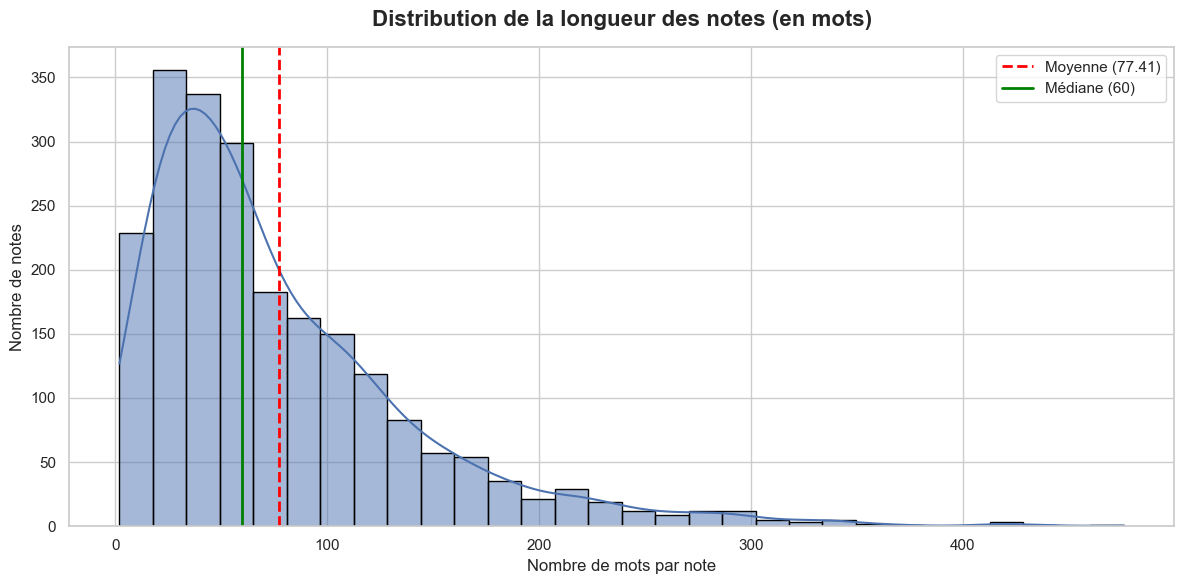

In [5]:
df = df.dropna(subset=[colonne_notes]).copy()
df[colonne_notes] = df[colonne_notes].astype(str).str.strip()
df = df[df[colonne_notes] != ""].copy()

df["longueur_mots"] = df[colonne_notes].str.split().str.len()

moyenne = df["longueur_mots"].mean()
mediane = df["longueur_mots"].median()
maximum = df["longueur_mots"].max()
minimum = df["longueur_mots"].min()
centile_90 = df["longueur_mots"].quantile(0.90)

print(f"Moyenne      : {moyenne:.2f} mots")
print(f"Médiane      : {mediane:.0f} mots")
print(f"Maximum      : {maximum} mots")
print(f"Minimum      : {minimum} mots")
print(f"90e Centile  : {centile_90:.0f} mots")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="longueur_mots",
    bins=30,
    kde=True,
    color="#4C72B0",
    edgecolor="black"
)

plt.axvline(moyenne, color="red", linestyle="--", linewidth=2, label=f"Moyenne ({moyenne:.2f})")
plt.axvline(mediane, color="green", linestyle="-", linewidth=2, label=f"Médiane ({mediane:.0f})")

plt.title("Distribution de la longueur des notes (en mots)", fontsize=16, pad=15, fontweight="bold")
plt.xlabel("Nombre de mots par note", fontsize=12)
plt.ylabel("Nombre de notes", fontsize=12)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

In [6]:
import sys
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.append(str(project_root))

from src.config import MODEL_NAME

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

df["longueur_tokens"] = df[colonne_notes].apply(
    lambda x: len(tokenizer(str(x), truncation=False)["input_ids"])
)

print(f"Moyenne tokens     : {df['longueur_tokens'].mean():.2f}")
print(f"Médiane tokens     : {df['longueur_tokens'].median():.0f}")
print(f"90e centile tokens : {df['longueur_tokens'].quantile(0.90):.0f}")
print(f"95e centile tokens : {df['longueur_tokens'].quantile(0.95):.0f}")
print(f"Maximum tokens     : {df['longueur_tokens'].max()}")
print(f"% > 256 tokens     : {(df['longueur_tokens'] > 256).mean() * 100:.2f}%")
print(f"% > 384 tokens     : {(df['longueur_tokens'] > 384).mean() * 100:.2f}%")
print(f"% > 512 tokens     : {(df['longueur_tokens'] > 512).mean() * 100:.2f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (546 > 512). Running this sequence through the model will result in indexing errors


Moyenne tokens     : 136.92
Médiane tokens     : 103
90e centile tokens : 283
95e centile tokens : 359
Maximum tokens     : 835
% > 256 tokens     : 12.28%
% > 384 tokens     : 4.05%
% > 512 tokens     : 1.14%


In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [5]:
print(f"Chargement du modèle {MODEL_NAME}...")

import os
os.environ["HF_HUB_DISABLE_XET"] = "1"

from transformers import AutoModelForSequenceClassification

print(f"Chargement du modèle {MODEL_NAME}...")
model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, 
        num_labels=2
    )

NameError: name 'MODEL_NAME' is not defined

In [6]:
MODEL_NAME = "almanach/camembert-bio-base"




print(f"Chargement du modèle {MODEL_NAME}...")

import os

os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"


from transformers import AutoModelForSequenceClassification


print(f"Chargement du modèle {MODEL_NAME}...")

model = AutoModelForSequenceClassification.from_pretrained(

        MODEL_NAME,

        num_labels=2

    )
print("Modèle chargé !")

Chargement du modèle almanach/camembert-bio-base...


c:\Users\leclou\Desktop\projet-dereev\venv\Lib\site-packages\huggingface_hub\constants.py:298: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Chargement du modèle almanach/camembert-bio-base...


config.json:   0%|          | 0.00/710 [00:00<?, ?B/s]

c:\Users\leclou\Desktop\projet-dereev\venv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\leclou\.cache\huggingface\hub\models--almanach--camembert-bio-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: almanach/camembert-bio-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modèle chargé !


In [ ]:
import os

os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "debug"

from transformers import AutoModelForSequenceClassification
from huggingface_hub import snapshot_download

print(f"Téléchargement de {MODEL_NAME}...")

local_path = snapshot_download(
    repo_id=MODEL_NAME,
    token=os.getenv("HF_TOKEN"),
)

print("Téléchargement terminé. Chargement en mémoire...")

model = AutoModelForSequenceClassification.from_pretrained(
    local_path,
    num_labels=2,
)

print("Modèle chargé.")

Téléchargement de almanach/camembert-bio-base...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

c:\Users\leclou\Desktop\projet-dereev\venv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\leclou\.cache\huggingface\hub\models--almanach--camembert-bio-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
